In [1]:
!git clone https://github.com/EPFL-IMOS/AnomalyAny

Cloning into 'AnomalyAny'...
remote: Enumerating objects: 87, done.
remote: Counting objects: 100% (34/34), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 87 (delta 26), reused 19 (delta 19), pack-reused 53 (from 1)
Receiving objects: 100% (87/87), 17.84 MiB | 34.07 MiB/s, done.
Resolving deltas: 100% (29/29), done.


In [2]:
!pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:06
🔁 Restarting kernel...


In [4]:
import os
os.chdir('AnomalyAny')
print("현재 디렉토리:", os.getcwd())

현재 디렉토리: /content/AnomalyAny


In [4]:
!conda env update -n base -f env.yml

Retrieving notices: - done
Channels:
 - pytorch
 - nvidia
 - defaults
 - conda-forge
Platform: linux-64

SpecsConfigurationConflictError: Requested specs conflict with configured specs.
  requested specs: 
    - _libgcc_mutex==0.1=main
    - _openmp_mutex==5.1=1_gnu
    - blas==1.0=mkl
    - brotlipy==0.7.0=py310h7f8727e_1002
    - bzip2==1.0.8=h7b6447c_0
    - ca-certificates==2023.05.30=h06a4308_0
    - certifi==2023.5.7=py310h06a4308_0
    - cffi==1.15.1=py310h5eee18b_3
    - charset-normalizer==2.0.4=pyhd3eb1b0_0
    - cryptography==39.0.1=py310h9ce1e76_0
    - cuda==11.6.1=0
    - cuda-cccl==11.6.55=hf6102b2_0
    - cuda-command-line-tools==11.6.2=0
    - cuda-compiler==11.6.2=0
    - cuda-cudart==11.6.55=he381448_0
    - cuda-cudart-dev==11.6.55=h42ad0f4_0
    - cuda-cuobjdump==11.6.124=h2eeebcb_0
    - cuda-cupti==11.6.124=h86345e5_0
    - cuda-cuxxfilt==11.6.124=hecbf4f6_0
    - cuda-driver-dev==11.6.55=0
    - cuda-gdb==12.1.105=0
    - cuda-libraries==11.6.1=0
    - cuda-li

**Reference:** 이 코드는 EPFL-IMOS의 [AnomalyAny GitHub 리포지토리](https://github.com/EPFL-IMOS/AnomalyAny)에서 가져왔습니다.

In [2]:
!pip install git+https://github.com/openai/CLIP.git pyrallis

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-vrhosra9
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-vrhosra9
  Resolved https://github.com/openai/CLIP.git to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached pyrallis-0.3.1-py3-none-any.whl.metadata (17 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 801.6/801.6 kB 15.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 807.9/807.9 kB 19.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 80.6 MB/s  0:00:04
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 33.1 MB/s  0:00:09
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 114.0 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 114.0 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [10]:
import sys
import os
import types
import importlib

# Python 3.12+에서 제거된 imp 모듈을 우회하기 위한 가짜(dummy) 모듈 등록 패치
if "imp" not in sys.modules:
    imp_mock = types.ModuleType("imp")
    imp_mock.reload = importlib.reload
    sys.modules["imp"] = imp_mock

# transformers 버전 호환성 패치
import transformers
if not hasattr(transformers, "CLIPFeatureExtractor"):
    try:
        from transformers import CLIPImageProcessor
        transformers.CLIPFeatureExtractor = CLIPImageProcessor
        sys.modules["transformers"].CLIPFeatureExtractor = CLIPImageProcessor
    except ImportError:
        pass

from typing import List, Dict
import torch

from clip_pipeline_attend_and_excite import RelationalAttendAndExcitePipeline
from config import RunConfig
from run import run_on_prompt, get_indices_to_alter, run_on_prompt_and_image, run_on_prompt_and_masked_image
from utils import vis_utils
from utils.ptp_utils import AttentionStore, show_cross_attention_binary

from utils.vis_utils import vis_ann

from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
NUM_DIFFUSION_STEPS = 50
GUIDANCE_SCALE = 12.5
MAX_NUM_WORDS = 77
device = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')
stable = RelationalAttendAndExcitePipeline.from_pretrained("runwayml/stable-diffusion-v1-5", safety_checker=None).to(device)
tokenizer = stable.tokenizer

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'clip_pipeline_attend_and_excite.RelationalAttendAndExcitePipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


# 1. 입력과 생성 조건
기본 입력은 저장소의 헤이즐넛 이미지입니다. 편집 위치를 제한하지 않고, 생성된 결함과 attention의 위치 관계를 관찰합니다.

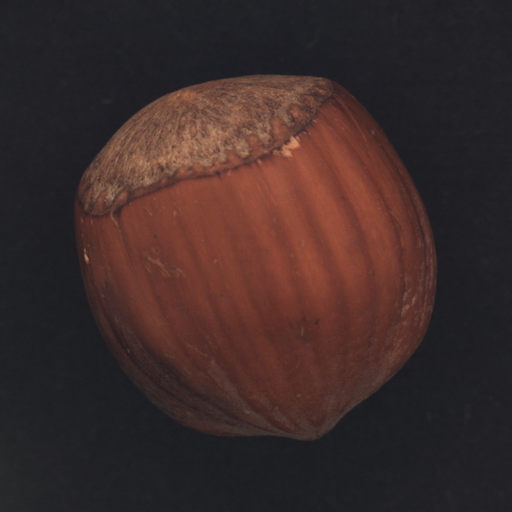

In [12]:
from pathlib import Path
import csv
from datetime import datetime
import gc
import importlib.metadata as metadata
import json
import random
import uuid

import matplotlib.pyplot as plt
from matplotlib import colors
import numpy as np
from PIL import Image
from IPython.display import display

PROJECT_DIR = Path.cwd().resolve()
NOTEBOOK_ROOT = PROJECT_DIR.parent
MODEL_ID = "runwayml/stable-diffusion-v1-5"
SEEDS = [42, 123, 2026, 7, 99]
IMAGE_SIZE = (512, 512)
ATTENTION_RESOLUTION = 16
INPUT_IMAGE_PATH = PROJECT_DIR / "example_image" / "000.png"
PROMPT = "a photo of a hazelnut with a crack on it"
NORMAL_PROMPT = "a photo of a hazelnut"
DETAILED_PROMPT = "a photo of a hazelnut with a large, jagged crack exposing the interior."
DEFECT_WORD = "crack"
INIT_IMAGE_GUIDANCE_SCALE = 0.3
SCALE_FACTOR = 50

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "figure.facecolor": "white", "savefig.facecolor": "white"})
torch.backends.cudnn.benchmark = False
with Image.open(INPUT_IMAGE_PATH) as source:
    input_image = source.convert("RGB").resize(IMAGE_SIZE, Image.Resampling.LANCZOS)
display(input_image)


In [14]:
def run_and_display(prompts: List[str],
                    controller: AttentionStore,
                    indices_to_alter: List[int],
                    init_image: Image.Image,
                    init_image_guidance_scale: float,
                    mask_image: str,
                    generator: torch.Generator,
                    run_standard_sd: bool = False,
                    scale_factor: int = 20,
                    thresholds: Dict[int, float] = {0: 0.05, 10: 0.5, 20: 0.8},
                    max_iter_to_alter: int = 25,
                    display_output: bool = False,
                    normal_prompt=NORMAL_PROMPT,
                    detailed_prompt=DETAILED_PROMPT):
    config = RunConfig(prompt=prompts[0],
                       run_standard_sd=run_standard_sd,
                       scale_factor=scale_factor,
                       thresholds=thresholds,
                       max_iter_to_alter=max_iter_to_alter,
                       n_inference_steps=NUM_DIFFUSION_STEPS,
                       guidance_scale=GUIDANCE_SCALE)
    image, image_latent = run_on_prompt_and_masked_image(model=stable,
                          prompt=prompts,
                          controller=controller,
                          token_indices=indices_to_alter,
                          init_image=init_image,
                          init_image_guidance_scale=init_image_guidance_scale,
                          mask_image=mask_image,
                          seed=generator,
                          config=config,
                          normal_prompt=normal_prompt,
                          detailed_prompt=detailed_prompt)
    if display_output:
        display(image)
    return image, image_latent

# 2. 이미지와 Attention 저장
마지막 UNet 실행의 조건부 cross-attention에서 결함 단어의 head·layer 평균을 16×16 크기로 추출합니다. 전체 생성 단계의 평균이나 결함 정답 마스크는 아닙니다.
이미지, 원본 attention 배열(.npy), seed와 설정을 실행별 폴더에 저장합니다.

In [15]:
def paired_generator(seed, generator_device):
    random.seed(int(seed))
    np.random.seed(int(seed))
    torch.manual_seed(int(seed))
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(int(seed))
    return torch.Generator(device=generator_device).manual_seed(int(seed))


def find_defect_tokens(tokenizer, prompt, defect_word):
    ids = tokenizer(prompt)["input_ids"]
    target_ids = tokenizer(defect_word, add_special_tokens=False)["input_ids"]
    if not target_ids:
        raise ValueError("DEFECT_WORD가 비어 있습니다.")
    starts = [i for i in range(1, len(ids) - len(target_ids))
              if ids[i:i + len(target_ids)] == target_ids]
    if len(starts) != 1:
        raise ValueError(f"프롬프트에서 {defect_word!r} 토큰을 하나로 특정할 수 없습니다.")
    return list(range(starts[0], starts[0] + len(target_ids)))


def extract_defect_attention(controller, token_indices, resolution, use_cfg):
    # 원본 AttentionStore의 get_average_attention()은 마지막 완료 forward를 반환합니다.
    # CFG의 무조건부·조건부 batch를 섞지 않고 조건부 head만 선택합니다.
    store = controller.get_average_attention()
    branches = 2 if use_cfg else 1
    selected_branch = 1 if use_cfg else 0
    layer_maps = []
    heads_per_layer = []
    if not token_indices or len(set(token_indices)) != len(token_indices):
        raise ValueError("결함 토큰 인덱스를 확인하세요.")
    for location in ("up", "down", "mid"):
        for item in store.get(f"{location}_cross", []):
            if item.ndim != 3:
                raise ValueError("예상한 cross-attention 배열 형태가 아닙니다.")
            if item.shape[1] != resolution ** 2:
                continue
            if item.shape[0] % branches:
                raise ValueError("CFG batch와 attention head 수가 맞지 않습니다.")
            if min(token_indices) < 0 or max(token_indices) >= item.shape[-1]:
                raise ValueError("결함 토큰이 attention 범위를 벗어났습니다.")
            per_branch = item.detach().float().reshape(
                branches, -1, resolution, resolution, item.shape[-1])
            conditional = per_branch[selected_branch]
            layer_maps.append(conditional[..., token_indices].mean(dim=-1).mean(dim=0).cpu())
            heads_per_layer.append(int(conditional.shape[0]))
    if not layer_maps:
        raise RuntimeError(f"{resolution}×{resolution} cross-attention이 저장되지 않았습니다.")
    raw = torch.stack(layer_maps).mean(dim=0).numpy().astype(np.float32)
    if not np.isfinite(raw).all() or np.any(raw < 0):
        raise RuntimeError("유효하지 않은 attention 값이 포함되어 있습니다.")
    info = {"source": "last completed UNet forward; not an average over denoising steps",
            "branch": "conditional only" if use_cfg else "single conditional branch",
            "aggregation": "mean over selected tokens, heads, then layers",
            "resolution": int(resolution), "token_indices": list(token_indices),
            "layers_used": len(layer_maps), "heads_per_layer": heads_per_layer}
    return raw, info


def write_records(folder, records):
    with (folder / "results.csv").open("w", encoding="utf-8-sig", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=["seed", "image_file", "attention_file", "attention_info_file"])
        writer.writeheader()
        writer.writerows(records)


def installed_version(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None


def run_attention_experiment(seeds, output_root):
    if len(seeds) != 5 or len(set(seeds)) != 5:
        raise ValueError("서로 다른 seed 5개를 지정하세요.")
    token_indices = find_defect_tokens(stable.tokenizer, PROMPT, DEFECT_WORD)
    run_id = datetime.now().strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:6]
    folder = Path(output_root) / run_id
    folder.mkdir(parents=True, exist_ok=False)
    for name in ("images", "attention", "comparisons"):
        (folder / name).mkdir()
    input_image.save(folder / "input.png")
    settings = {"status": "running", "completed": 0, "planned": len(seeds),
        "seeds": [int(seed) for seed in seeds], "prompt": PROMPT,
        "normal_prompt": NORMAL_PROMPT, "detailed_prompt": DETAILED_PROMPT,
        "defect_word": DEFECT_WORD, "token_indices": token_indices,
        "image_size": list(input_image.size), "mask_image": None,
        "attention_resolution": ATTENTION_RESOLUTION,
        "attention_source": "last completed UNet forward; conditional CFG branch only",
        "num_diffusion_steps": NUM_DIFFUSION_STEPS, "guidance_scale": GUIDANCE_SCALE,
        "init_image_guidance_scale": INIT_IMAGE_GUIDANCE_SCALE,
        "scale_factor": SCALE_FACTOR, "max_iter_to_alter": 25,
        "thresholds": {0: 0.05, 10: 0.5, 20: 0.8},
        "model_id": MODEL_ID,
        "versions": {name: installed_version(name) for name in
                     ("torch", "torchvision", "diffusers", "transformers", "accelerate", "numpy")}}
    settings_path = folder / "settings.json"
    settings_path.write_text(json.dumps(settings, ensure_ascii=False, indent=2), encoding="utf-8")
    records = []
    config = RunConfig(prompt=PROMPT, run_standard_sd=False,
        scale_factor=SCALE_FACTOR, thresholds={0: 0.05, 10: 0.5, 20: 0.8},
        max_iter_to_alter=25, n_inference_steps=NUM_DIFFUSION_STEPS,
        guidance_scale=GUIDANCE_SCALE)
    print("결과 저장 위치:", folder)
    try:
        for seed in seeds:
            print(f"[{len(records) + 1}/{len(seeds)}] seed={seed}")
            generator = paired_generator(seed, device)
            controller = AttentionStore()
            image, image_tensor = run_on_prompt_and_masked_image(
                prompt=[PROMPT], model=stable, controller=controller,
                token_indices=token_indices, init_image=input_image.copy(),
                init_image_guidance_scale=INIT_IMAGE_GUIDANCE_SCALE,
                mask_image=None, seed=generator, config=config,
                normal_prompt=NORMAL_PROMPT, detailed_prompt=DETAILED_PROMPT)
            if image.size != input_image.size:
                raise RuntimeError(f"출력 크기가 다릅니다: {image.size}")
            raw, info = extract_defect_attention(
                controller, token_indices, ATTENTION_RESOLUTION, GUIDANCE_SCALE > 1)
            image_file = f"images/seed_{int(seed)}.png"
            attention_file = f"attention/seed_{int(seed)}_raw.npy"
            info_file = f"attention/seed_{int(seed)}_info.json"
            image.save(folder / image_file)
            np.save(folder / attention_file, raw, allow_pickle=False)
            (folder / info_file).write_text(json.dumps(info, indent=2), encoding="utf-8")
            records.append({"seed": int(seed), "image_file": image_file,
                            "attention_file": attention_file, "attention_info_file": info_file})
            write_records(folder, records)
            settings["completed"] = len(records)
            settings_path.write_text(json.dumps(settings, ensure_ascii=False, indent=2), encoding="utf-8")
            controller.reset()
            del image, image_tensor, controller, generator
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    except Exception as error:
        settings.update(status="failed", error=f"{type(error).__name__}: {error}")
        settings_path.write_text(json.dumps(settings, ensure_ascii=False, indent=2), encoding="utf-8")
        print("저장된 결과는 위 폴더에서 확인할 수 있습니다.")
        raise
    settings["status"] = "complete"
    settings_path.write_text(json.dumps(settings, ensure_ascii=False, indent=2), encoding="utf-8")
    return folder, records


In [16]:
result_directory, result_records = run_attention_experiment(
    SEEDS, NOTEBOOK_ROOT / "attention_location_results")
print(f"완료: {len(result_records)}장 / {result_directory}")

결과 저장 위치: /content/attention_location_results/20261017_161432_3c2e01
[1/5] seed=42


100%|████████████████████████████████████████| 890M/890M [00:05<00:00, 163MiB/s]
/usr/local/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
100%|████████████████████████████████████████| 244M/244M [00:01<00:00, 178MiB/s]
/content/AnomalyAny/clip_pipeline_attend_and_excite.py:712: FutureWarning: Accessing config attribute `in_channels` directly via 'UNet2DConditionModel' object attribute is deprecated. Please access 'in_channels' over 'UNet2DConditionModel's config object instead, e.g. 'unet.config.in_channels'.
  num_channels_latents = self.unet.in_channels


  0%|          | 0/50 [00:00<?, ?it/s]

[2/5] seed=123


  0%|          | 0/50 [00:00<?, ?it/s]

...

[4/5] seed=7


  0%|          | 0/50 [00:00<?, ?it/s]

[5/5] seed=99


  0%|          | 0/50 [00:00<?, ?it/s]

완료: 5장 / /content/attention_location_results/20261017_161432_3c2e01


#3. 결함 위치와 나란히 비교
생성 이미지에서 결함이 실제로 보이는지 먼저 확인합니다. 아래 좌표 표시는 선택 사항입니다.
직접 확인한 결함의 (x, y) 좌표를 seed별로 넣으면 같은 위치를 세 패널에 표시합니다. 기준은 512×512 이미지의 왼쪽 위입니다.
좌표를 수정한 뒤 이 셀과 다음 셀만 다시 실행하면 됩니다.

In [17]:
# 형식: {seed: [(x, y), ...]}. 직접 확인한 위치만 입력합니다.
DEFECT_POINTS_BY_SEED = {}

In [18]:
def validate_defect_points(points_by_seed, seeds, size):
    if set(points_by_seed) - {int(seed) for seed in seeds}:
        raise ValueError("직접 확인한 결함 좌표의 seed가 생성 목록에 없습니다.")
    width, height = size
    for seed, points in points_by_seed.items():
        for point in points:
            if len(point) != 2:
                raise ValueError("결함 좌표는 (x, y) 형식입니다.")
            x, y = point
            if not (np.isfinite(x) and np.isfinite(y) and 0 <= x < width and 0 <= y < height):
                raise ValueError(f"seed {seed}: 결함 좌표가 이미지 범위를 벗어났습니다.")


def draw_defect_points(axis, points):
    for index, (x, y) in enumerate(points, 1):
        axis.scatter([x + 0.5], [y + 0.5], s=130, facecolors="none",
                     edgecolors="#00b4d8", linewidths=1.8)
        width = max(axis.get_xlim())
        height = max(axis.get_ylim())
        offset = (-27 if x > width * 0.85 else 7, -14 if y < height * 0.15 else 7)
        axis.annotate(f"D{index}", (x + 0.5, y + 0.5), xytext=offset,
                      textcoords="offset points", color="white", fontsize=9,
                      bbox={"facecolor": "black", "alpha": 0.65, "pad": 1.5})


def attention_overlay(image, raw, vmax):
    # 16×16 원본은 별도로 보존하고, 확대는 시각화에만 사용합니다.
    enlarged = np.asarray(Image.fromarray(raw).resize(image.size, Image.Resampling.BILINEAR))
    strength = np.clip(enlarged / vmax, 0, 1)
    heat = plt.get_cmap("magma")(strength)[..., :3]
    alpha = strength[..., None] * 0.6
    source = np.asarray(image).astype(np.float32) / 255.0
    return Image.fromarray(np.rint(np.clip(source * (1 - alpha) + heat * alpha, 0, 1) * 255).astype(np.uint8))


def draw_comparison_row(axes, image, raw, vmax, seed, points):
    width, height = image.size
    extent = (0, width, height, 0)
    overlay = attention_overlay(image, raw, vmax)
    axes[0].imshow(image, extent=extent)
    axes[1].imshow(raw, cmap="magma", vmin=0, vmax=vmax,
                    interpolation="nearest", extent=extent)
    axes[2].imshow(overlay, extent=extent)
    for axis, title in zip(axes, ("Generated image", "Conditional attention (16 x 16)", "Attention overlay")):
        axis.set_title(f"{title} | seed {seed}", fontsize=10)
        draw_defect_points(axis, points)
        axis.set_xlim(0, width)
        axis.set_ylim(height, 0)
        axis.set_axis_off()
    return overlay


def render_attention_comparisons(folder, records, seeds, defect_points_by_seed):
    folder = Path(folder)
    lookup = {int(row["seed"]): row for row in records}
    if set(lookup) != {int(seed) for seed in seeds} or len(records) != len(seeds):
        raise ValueError("seed 5개의 이미지와 attention이 모두 있어야 합니다.")
    validate_defect_points(defect_points_by_seed, seeds, IMAGE_SIZE)
    raw_maps = {seed: np.load(folder / row["attention_file"], allow_pickle=False)
                for seed, row in lookup.items()}
    if any(raw.shape != (ATTENTION_RESOLUTION, ATTENTION_RESOLUTION)
           or not np.isfinite(raw).all() or np.any(raw < 0) for raw in raw_maps.values()):
        raise ValueError("유효하지 않은 attention 파일입니다.")
    vmax = max(float(raw.max()) for raw in raw_maps.values())
    if vmax <= 0:
        raise ValueError("attention 값이 모두 0입니다.")
    fig, axes = plt.subplots(len(seeds), 3, figsize=(12, 4 * len(seeds)),
                             squeeze=False, constrained_layout=True)
    for index, seed in enumerate(seeds):
        row = lookup[int(seed)]
        with Image.open(folder / row["image_file"]) as source:
            image = source.convert("RGB")
        if image.size != IMAGE_SIZE:
            raise ValueError("생성 이미지와 좌표 기준 크기가 다릅니다.")
        raw = raw_maps[int(seed)]
        points = defect_points_by_seed.get(int(seed), [])
        overlay = draw_comparison_row(axes[index], image, raw, vmax, seed, points)
        overlay.save(folder / "comparisons" / f"seed_{int(seed)}_overlay.png")
        one, one_axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
        draw_comparison_row(one_axes, image, raw, vmax, seed, points)
        one.colorbar(plt.cm.ScalarMappable(norm=colors.Normalize(0, vmax), cmap="magma"),
                      ax=list(one_axes), shrink=0.7, label="Cross-attention weight")
        one.savefig(folder / "comparisons" / f"seed_{int(seed)}_comparison.png", dpi=150)
        plt.close(one)
    fig.colorbar(plt.cm.ScalarMappable(norm=colors.Normalize(0, vmax), cmap="magma"),
                  ax=list(axes[:, 1]), shrink=0.55, label="Cross-attention weight")
    fig.suptitle("Generated image and defect-word attention | one shared color scale", fontsize=14)
    fig.savefig(folder / "attention_comparison_grid.png", dpi=130)
    annotations = {str(seed): [list(point) for point in points]
                   for seed, points in defect_points_by_seed.items()}
    (folder / "human_defect_points.json").write_text(json.dumps({
        "source": "optional points manually identified in generated images; not attention-derived",
        "coordinate_space": "generated-image pixels, top-left origin, x right, y down",
        "points_by_seed": annotations, "shared_attention_vmax": vmax}, indent=2), encoding="utf-8")
    return fig


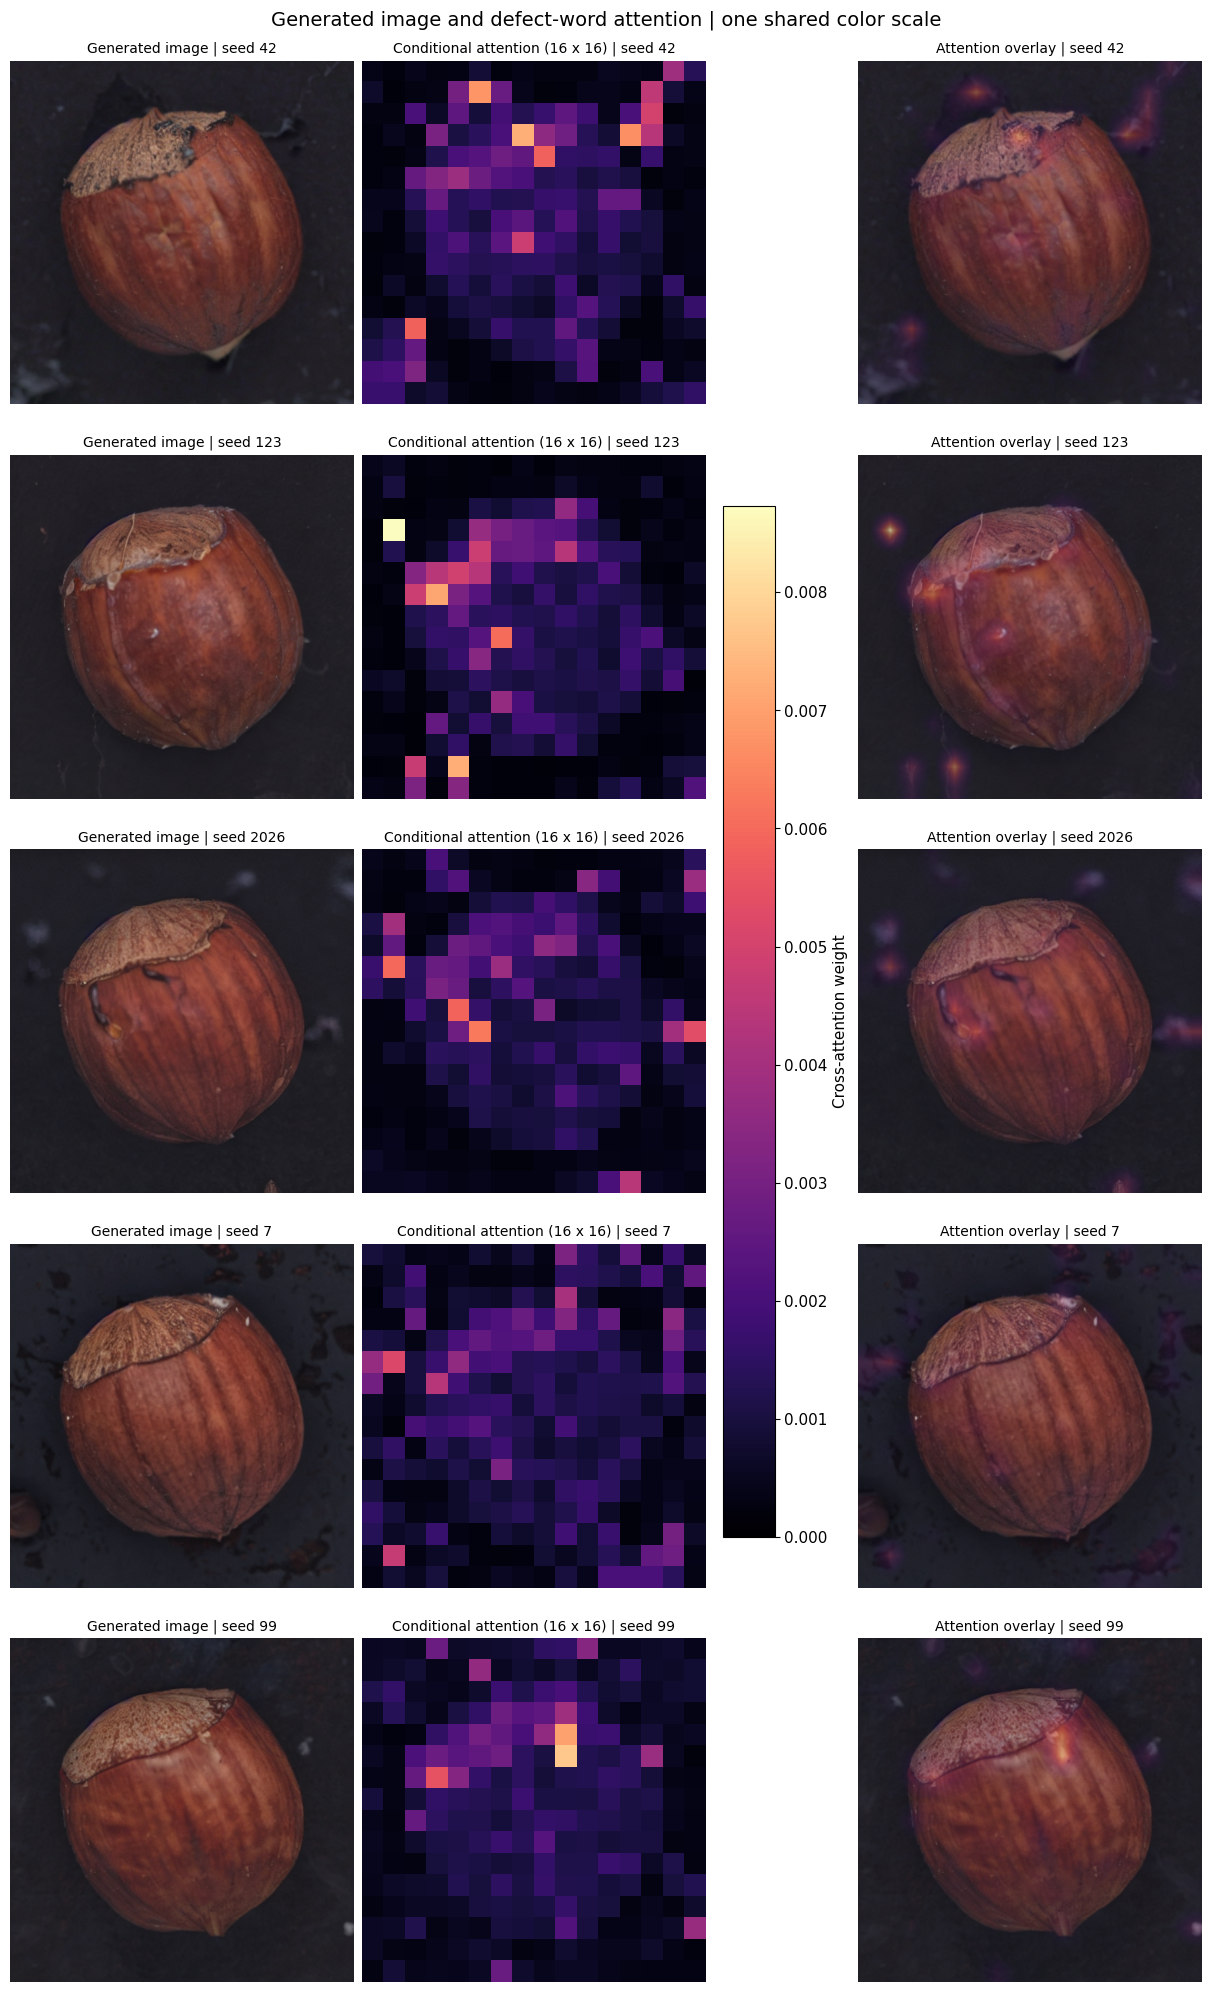

비교 이미지 저장: /content/attention_location_results/20261017_161432_3c2e01/attention_comparison_grid.png


In [19]:
comparison_figure = render_attention_comparisons(
    result_directory, result_records, SEEDS, DEFECT_POINTS_BY_SEED)
plt.show()
plt.close(comparison_figure)
print("비교 이미지 저장:", result_directory / "attention_comparison_grid.png")
